In [25]:
import cv2
import numpy as np
import os
import sys
from pathlib import Path
from insightface.app import FaceAnalysis

app = FaceAnalysis(name="buffalo_l")
app.prepare(ctx_id=-1, det_size=(640, 640))  # Use ctx_id=-1 for CPU

anna_embedding_array = []
for image_path in Path("images/people/anna").iterdir():
    image = cv2.imread(image_path)
    anna_embedding_array.append(app.get(image)[0].normed_embedding)

edouard_embedding_array = []
for image_path in Path("images/people/edouard").iterdir():
    image = cv2.imread(image_path)
    edouard_embedding_array.append(app.get(image)[0].normed_embedding)

katia_embedding_array = []
for image_path in Path("images/people/katia").iterdir():
    image = cv2.imread(image_path)
    katia_embedding_array.append(app.get(image)[0].normed_embedding)


katia_embedding = np.mean(katia_embedding_array, axis=0)
anna_embedding = np.mean(anna_embedding_array, axis=0)
edouard_embedding = np.mean(edouard_embedding_array, axis=0)


/home/robin/EPFL/MA3/machineLearning/Who_that/.venv/lib/python3.12/site-packages/insightface/utils/face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


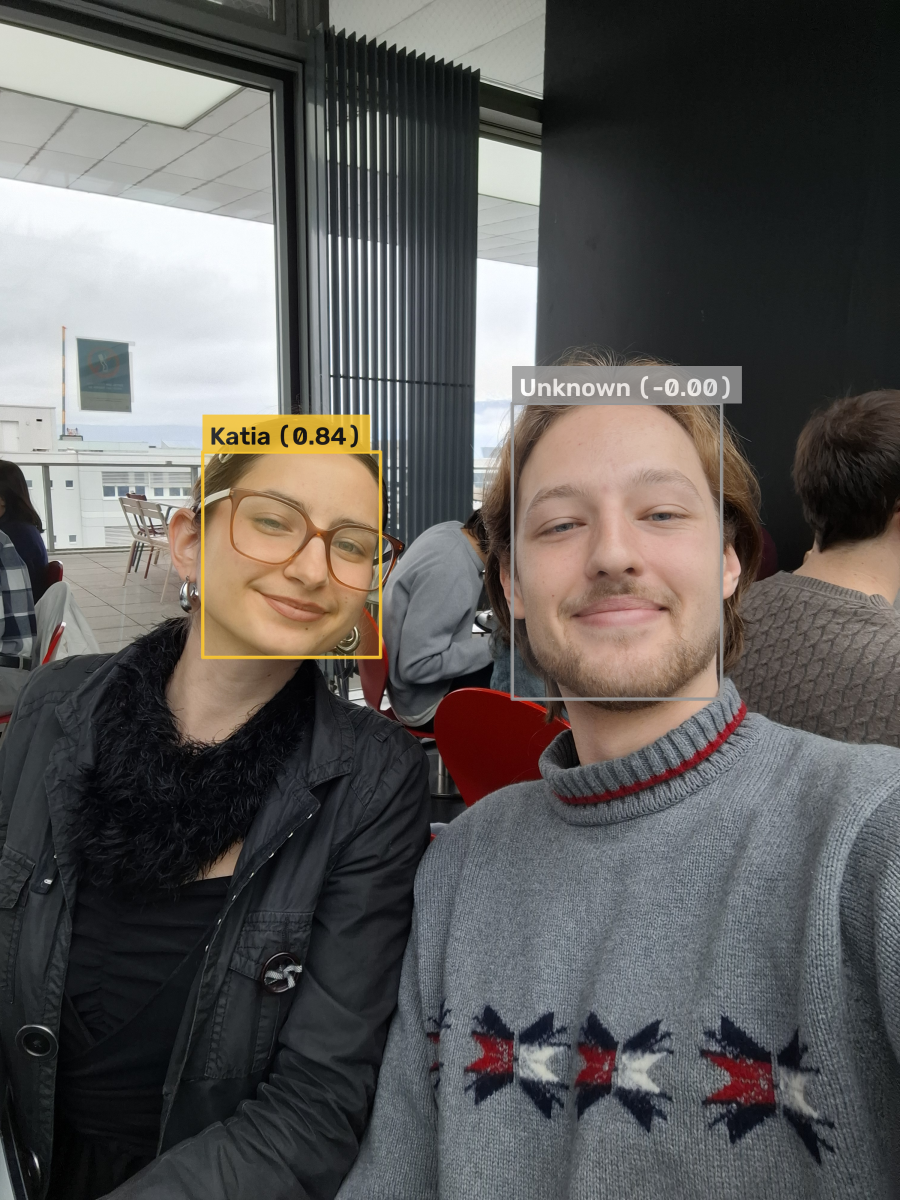

In [26]:
import cv2
import numpy as np
from IPython.display import display
from PIL import Image

# Distinct BGR colors for enrolled targets
DEFAULT_PALETTE = [
    (80, 210, 60),    # Green
    (235, 180, 50),   # Sky Blue
    (50, 195, 245),   # Amber
    (130, 105, 245),  # Coral
    (225, 130, 185),  # Lavender
    (170, 225, 90),   # Mint
]


def show_face_overlay(
    img_bgr: np.ndarray,
    faces: list,
    gallery: dict[str, np.ndarray],
    threshold: float = 0.45,
    show_unknown: bool = True,
    max_display_width: int = 900,
    palette: list[tuple[int, int, int]] = DEFAULT_PALETTE,
):
    canvas = img_bgr.copy()
    overlay = img_bgr.copy()
    h, w = canvas.shape[:2]

    # Stack and ensure L2-normalization for all gallery embeddings: shape (N, 512)
    names = list(gallery.keys())
    if names:
        ref_matrix = np.vstack([gallery[name] for name in names])
        ref_matrix /= np.linalg.norm(ref_matrix, axis=1, keepdims=True)
    else:
        ref_matrix = np.empty((0, 512), dtype=np.float32)

    # Scale stroke and text dynamically to image dimensions
    scale = max(w, h) / 1000.0
    thickness = max(2, int(round(2.5 * scale)))
    font_scale = max(0.55, 0.7 * scale)
    font = cv2.FONT_HERSHEY_SIMPLEX

    for face in faces:
        if len(names) > 0:
            sims = ref_matrix @ face.normed_embedding
            best_idx = int(np.argmax(sims))
            best_sim = float(sims[best_idx])
            is_match = best_sim >= threshold
        else:
            best_idx, best_sim, is_match = -1, 0.0, False

        if not is_match and not show_unknown:
            continue

        x1, y1, x2, y2 = face.bbox.astype(int)
        if is_match:
            color = palette[best_idx % len(palette)]
            text = f"{names[best_idx]} ({best_sim:.2f})"
            text_color = (15, 15, 15)
        else:
            color = (150, 150, 150)
            text = f"Unknown ({best_sim:.2f})" if len(names) > 0 else "Unknown"
            text_color = (255, 255, 255)

        # Translucent box fill + crisp border
        cv2.rectangle(overlay, (x1, y1), (x2, y2), color, -1)
        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, thickness, cv2.LINE_AA)

        # Label badge positioned above the box (clamped inside top edge if needed)
        (tw, th), _ = cv2.getTextSize(text, font, font_scale, thickness)
        pad = max(4, int(6 * scale))
        badge_y1 = max(0, y1 - th - 2 * pad)
        badge_y2 = max(th + 2 * pad, y1)
        cv2.rectangle(canvas, (x1, badge_y1), (x1 + tw + 2 * pad, badge_y2), color, -1)

        cv2.putText(
            canvas,
            text,
            (x1 + pad, badge_y2 - pad),
            font,
            font_scale,
            text_color,
            max(1, thickness - 1),
            cv2.LINE_AA,
        )

    # Blend 15% box tint with crisp boxes/text
    vis = cv2.addWeighted(overlay, 0.15, canvas, 0.85, 0)

    # Downscale large photos for clean notebook output without altering detection coords
    if w > max_display_width:
        new_h = int(h * (max_display_width / w))
        vis = cv2.resize(vis, (max_display_width, new_h), interpolation=cv2.INTER_AREA)

    display(Image.fromarray(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)))


# Build your gallery from enrolled embeddings
gallery = {
    "Edouard": edouard_embedding,
    "Anna": anna_embedding,
    "Katia": katia_embedding,
}

# Run on your target image
target_img = cv2.imread("images/group.jpg")
detected_faces = app.get(target_img)

show_face_overlay(
    target_img,
    detected_faces,
    gallery=gallery,
    threshold=0.35,
    show_unknown=True,  # Set False to hide unmatched faces
)